In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

os.listdir("/content/drive/MyDrive")

['Red Modern Email Signature.png',
 'Black White Simple Photo Business Email Signature.png',
 'facebook (1).png',
 'facebook.png',
 'ABDUL BASIT.png',
 'Untitled document (1).gdoc',
 'vendor-sites.gsheet',
 'Untitled document.gdoc',
 'developing knowlwdge base using INSIGHT and EXPER....gsheet',
 'Colab Notebooks',
 '.ipynb_checkpoints',
 'Classroom',
 'my_model.keras',
 'MRI_images',
 'ADNIMERGE2']

In [ ]:
os.listdir("/content/drive/MyDrive/ADNIMERGE2/research_dataset")

['DXSUM_27Apr2026.csv',
 'BLCHANGE_27Apr2026.csv',
 'PTDEMOG_27Apr2026.csv',
 'UPENN_PLASMA_FUJIREBIO_QUANTERIX_27Apr2026.csv',
 'All_Subjects_APOERES_27Apr2026.csv',
 'All_Subjects_Key_MRI_27Apr2026.csv',
 'All_Subjects_Key_PET_27Apr2026.csv',
 'All_Subjects_UCBERKELEY_AMY_6MM_10May2026.csv',
 'clean_cn_amyloid_dataset.csv',
 'UCSFFSX7_22May2026.csv',
 'mri_5_23_2026.csv',
 'cn_mri_5_24_2026.csv',
 'with_examdate_dataset.csv']

# **DXSUM_27Apr2026.csv — Diagnosis / Cohort Dataset**

Purpose:

Main diagnostic and visit tracking dataset

Type:

Longitudinal clinical diagnosis data

Key Identifiers:

RID (Research ID)
PTID (Patient ID)
VISCODE (Visit timepoint)
EXAMDATE (Visit date)

Target / Important Column:

DIAGNOSIS → CN / MCI / AD (1 / 2 / 3)

Important Features:

DXNORM (normal cognition indicator)
DXMCI (mild cognitive impairment indicator)
DXMDES (dementia-related severity)
Other DXM* fields (clinical sub-scores / flags)

Key Insight:

One patient appears multiple times (longitudinal data)
Used for defining cohort + labels, not final ML features
_______________________________________________________________________________

**DXSUM_27Apr2026.csv**                          
PHASE → ADNI study phase/version                  
PTID → Patient ID                                    
RID → Research patient ID (main merge key)                        
VISCODE → Visit timepoint (bl, m06, m12, etc.)                         
VISCODE2 → Alternate visit code                         
EXAMDATE → Examination date                             
DIAGNOSIS → Clinical diagnosis (1=CN, 2=MCI, 3=AD)                     
DXNORM → Normal cognition indicator                                          
DXNODEP → Depression-related diagnosis indicator                         
DXMCI → Mild Cognitive Impairment indicator                         
DXMDES → Dementia indicator                                           
DXMPTR1–DXMPTR6 → Diagnostic pathway/clinical reasoning flags            
DXMDUE → Dementia etiology indicator                                 
DXMOTHET → Other etiology information                                
DXDSEV → Dementia severity score                                         

In [ ]:
import pandas as pd

dx = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/DXSUM_27Apr2026.csv"
)

In [ ]:
dx.head()

,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,DIAGNOSIS,DXNORM,DXNODEP,DXMCI,...,DXODES,DXCONFID,ID,SITEID,USERDATE,USERDATE2,DD_CRF_VERSION_LABEL,LANGUAGE_CODE,HAS_QC_ERROR,update_stamp
0,ADNI1,011_S_0002,2,bl,bl,2005-09-29,1.0,1.0,-4.0,-4.0,...,-4.0,4.0,2,107,2005-10-01,NaN,NaN,NaN,NaN,2005-10-01 00:00:00
1,ADNI1,011_S_0003,3,bl,bl,2005-09-30,3.0,-4.0,-4.0,-4.0,...,-4.0,3.0,4,107,2005-10-01,NaN,NaN,NaN,NaN,2005-10-01 00:00:00
2,ADNI1,011_S_0005,5,bl,bl,2005-09-30,1.0,1.0,-4.0,-4.0,...,-4.0,4.0,6,107,2005-10-01,NaN,NaN,NaN,NaN,2005-10-01 00:00:00
3,ADNI1,011_S_0008,8,bl,bl,2005-09-30,1.0,1.0,-4.0,-4.0,...,-4.0,3.0,8,107,2005-10-01,NaN,NaN,NaN,NaN,2005-10-01 00:00:00
4,ADNI1,022_S_0007,7,bl,bl,2005-10-06,3.0,-4.0,-4.0,-4.0,...,-4.0,4.0,10,10,2005-10-06,NaN,NaN,NaN,NaN,2005-10-06 00:00:00


In [ ]:
dx.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16077 entries, 0 to 16076
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PHASE                 16077 non-null  object 
 1   PTID                  16077 non-null  object 
 2   RID                   16077 non-null  int64  
 3   VISCODE               16077 non-null  object 
 4   VISCODE2              16068 non-null  object 
 5   EXAMDATE              15964 non-null  object 
 6   DIAGNOSIS             16032 non-null  float64
 7   DXNORM                3868 non-null   float64
 8   DXNODEP               3868 non-null   float64
 9   DXMCI                 3868 non-null   float64
 10  DXMDES                12004 non-null  object 
 11  DXMPTR1               8750 non-null   float64
 12  DXMPTR2               8734 non-null   float64
 13  DXMPTR3               8740 non-null   float64
 14  DXMPTR4               8747 non-null   float64
 15  DXMPTR5            

In [ ]:
dx["DIAGNOSIS"].value_counts()    #1.0 -> CN

,count
DIAGNOSIS,
2.0,6561
1.0,6462
3.0,3009


In [ ]:
dx["VISCODE"].value_counts()  #bl -baseline

,count
VISCODE,
bl,1645
v01,1056
sc,966
v11,942
m06,897
v21,815
v03,782
4_sc,741
m12,739


In [ ]:
dx["RID"].nunique()

3711

In [ ]:
len(dx)

16077

In [ ]:
baseline = dx[dx["VISCODE"] == "bl"]

In [ ]:
baseline.shape

(1645, 41)

In [ ]:
baseline["RID"].nunique()

1645

In [ ]:
len(baseline)

1645

In [ ]:
cn = baseline[baseline["DIAGNOSIS"] == 1]

In [ ]:

cn.shape

(608, 41)

**PET**

In [ ]:
import pandas as pd

df_pet = pd.read_csv("/content/drive/MyDrive/ADNIMERGE2/research_dataset/All_Subjects_UCBERKELEY_AMY_6MM_10May2026.csv")

In [ ]:
df_pet.sample(20)

,LONIUID,PTID,RID,VISCODE,VISCODE2,SCANDATE,SITEID,PROCESSDATE,IMAGE_RESOLUTION,qc_flag,...,RIGHT_PALLIDUM_VOLUME,RIGHT_PUTAMEN_SUVR,RIGHT_PUTAMEN_VOLUME,RIGHT_THALAMUS_PROPER_SUVR,RIGHT_THALAMUS_PROPER_VOLUME,RIGHT_VENTRALDC_SUVR,RIGHT_VENTRALDC_VOLUME,RIGHT_VESSEL_SUVR,RIGHT_VESSEL_VOLUME,update_stamp
2181,915578,018_S_4400,4400,init,m66,2017-09-29,18,2023-02-17,8mm,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-09-12 20:29:48
3253,1599150,072_S_5207,5207,v03,bl,2013-07-17,72,2022-12-23,6mm,2,...,2240.0,1.230,5135.0,0.989,5889.0,1.300,3884.0,1.194,10.0,2025-09-12 20:29:48
3255,1593492,003_S_5209,5209,v03,bl,2013-08-01,3,2022-09-05,6mm,2,...,1874.0,1.354,4333.0,1.341,5667.0,1.458,3449.0,1.542,10.0,2025-09-12 20:29:48
1188,1595803,021_S_2077,2077,bl,bl,2010-10-13,21,2022-09-06,6mm,2,...,2295.0,1.457,5447.0,1.258,6972.0,1.404,4246.0,1.295,9.0,2025-09-12 20:29:48
1624,1594733,012_S_4094,4094,v41,m48,2015-08-27,12,2022-09-06,6mm,2,...,1437.0,1.222,3309.0,1.103,5356.0,1.311,3175.0,0.993,4.0,2025-09-12 20:29:48
222,1634914,033_S_6352,6352,y4,m54,2022-10-13,33,2023-02-15,6mm,2,...,1912.0,1.284,5082.0,1.256,7504.0,1.516,4555.0,1.369,106.0,2025-09-12 20:29:48
388,1650247,941_S_6574,6574,y4,m48,2022-11-30,941,2023-05-26,6mm,2,...,1388.0,1.177,4189.0,1.172,5538.0,1.402,3392.0,1.135,7.0,2025-09-12 20:29:48
4380,11432025,031_S_10731,10731,4_bl,bl,2025-08-27,31,2025-09-11,6mm,2,...,2011.0,1.254,5140.0,1.226,7676.0,1.550,4505.0,1.250,3.0,2026-03-13 14:52:09
2792,1596558,027_S_4801,4801,v03,bl,2012-07-17,27,2022-09-06,6mm,2,...,2192.0,1.435,3813.0,1.086,6075.0,1.244,3310.0,1.257,48.0,2025-09-12 20:29:48
2101,1595161,019_S_4367,4367,y2,m90,2019-05-13,19,2022-09-06,6mm,2,...,1996.0,1.155,5012.0,1.162,7028.0,1.371,4211.0,1.110,17.0,2025-09-12 20:29:48


In [ ]:
df_pet.columns

Index(['LONIUID', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'SCANDATE', 'SITEID',
       'PROCESSDATE', 'IMAGE_RESOLUTION', 'qc_flag',
       ...
       'RIGHT_PALLIDUM_VOLUME', 'RIGHT_PUTAMEN_SUVR', 'RIGHT_PUTAMEN_VOLUME',
       'RIGHT_THALAMUS_PROPER_SUVR', 'RIGHT_THALAMUS_PROPER_VOLUME',
       'RIGHT_VENTRALDC_SUVR', 'RIGHT_VENTRALDC_VOLUME', 'RIGHT_VESSEL_SUVR',
       'RIGHT_VESSEL_VOLUME', 'update_stamp'],
      dtype='object', length=344)

In [ ]:
[col for col in df_pet.columns if "suvr" in col.lower()]

['TRACER_SUVR_WARNING',
 'SUMMARY_SUVR',
 'WHOLECEREBELLUM_SUVR',
 'COMPOSITE_REF_SUVR',
 'CEREBELLUM_CORTEX_SUVR',
 'ERODED_SUBCORTICALWM_SUVR',
 'BRAINSTEM_SUVR',
 'CC_ANTERIOR_SUVR',
 'CC_CENTRAL_SUVR',
 'CC_MID_ANTERIOR_SUVR',
 'CC_MID_POSTERIOR_SUVR',
 'CC_POSTERIOR_SUVR',
 'CSF_SUVR',
 'VENTRICLE_3RD_SUVR',
 'VENTRICLE_4TH_SUVR',
 'VENTRICLE_5TH_SUVR',
 'WM_HYPOINTENSITIES_SUVR',
 'NON_WM_HYPOINTENSITIES_SUVR',
 'CTX_BANKSSTS_SUVR',
 'CTX_CAUDALANTERIORCINGULATE_SUVR',
 'CTX_CAUDALMIDDLEFRONTAL_SUVR',
 'CTX_CUNEUS_SUVR',
 'CTX_ENTORHINAL_SUVR',
 'CTX_FRONTALPOLE_SUVR',
 'CTX_FUSIFORM_SUVR',
 'CTX_INFERIORPARIETAL_SUVR',
 'CTX_INFERIORTEMPORAL_SUVR',
 'CTX_INSULA_SUVR',
 'CTX_ISTHMUSCINGULATE_SUVR',
 'CTX_LATERALOCCIPITAL_SUVR',
 'CTX_LATERALORBITOFRONTAL_SUVR',
 'CTX_LINGUAL_SUVR',
 'CTX_MEDIALORBITOFRONTAL_SUVR',
 'CTX_MIDDLETEMPORAL_SUVR',
 'CTX_PARACENTRAL_SUVR',
 'CTX_PARAHIPPOCAMPAL_SUVR',
 'CTX_PARSOPERCULARIS_SUVR',
 'CTX_PARSORBITALIS_SUVR',
 'CTX_PARSTRIANGULARIS_SUVR',


In [ ]:
df_pet["SUMMARY_SUVR"].describe()

,SUMMARY_SUVR
count,4715.000000
mean,1.186190
std,0.256397
min,0.797000
25%,0.989000
50%,1.072000
75%,1.362000
max,2.842000


<Axes: >

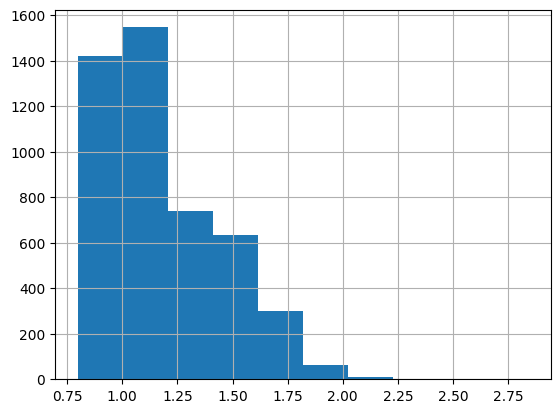

In [ ]:
df_pet["SUMMARY_SUVR"].hist()

In [ ]:
df_pet["SUMMARY_SUVR"].describe()

,SUMMARY_SUVR
count,4715.000000
mean,1.186190
std,0.256397
min,0.797000
25%,0.989000
50%,1.072000
75%,1.362000
max,2.842000


In [ ]:
df_pet[["RID", "VISCODE", "SUMMARY_SUVR"]].head()

,RID,VISCODE,SUMMARY_SUVR
0,767,init,1.034
1,4214,init,0.977
2,4214,y2,0.987
3,4214,y4,1.000
4,4485,y2,1.454


In [ ]:
df_pet["SUMMARY_SUVR"].isnull().sum()

np.int64(12)

In [ ]:
df_plasma = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/UPENN_PLASMA_FUJIREBIO_QUANTERIX_27Apr2026.csv"
)

df_plasma.head()


,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,Primary,Additive,pT217_F,AB42_F,AB40_F,AB42_AB40_F,pT217_AB42_F,NfL_Q,GFAP_Q,NfL_F,GFAP_F,Comment,update_stamp
0,ADNI1,011_S_0002,2,bl,bl,9/8/2005,BLD,EDT,0.199,27.92,324.12,0.086100,0.007130,14.9,94.6,-4.0,-4.0,NaN,2/9/2026 8:23
1,ADNI1,011_S_0008,8,bl,bl,9/19/2005,BLD,EDT,0.152,27.90,296.53,0.094088,0.005448,26.6,141.1,-4.0,-4.0,NaN,2/9/2026 8:23
2,ADNI2,011_S_0008,8,v41,m120,10/29/2015,BLD,EDT,0.235,7.24,70.00,0.103429,0.032459,55.8,289.1,-4.0,-4.0,NaN,2/9/2026 8:23
3,ADNI1,011_S_0010,10,bl,bl,11/10/2005,BLD,EDT,0.472,24.44,332.15,0.073581,0.019313,26.5,194.3,-4.0,-4.0,NaN,2/9/2026 8:23
4,ADNI1,011_S_0010,10,m24,m24,11/7/2007,BLD,EDT,0.586,19.61,288.14,0.068057,0.029883,30.2,221.3,-4.0,-4.0,NaN,2/9/2026 8:23



**UPENN_PLASMA_FUJIREBIO_QUANTERIX_27Apr2026.csv**

🧠 Purpose                                                               
Blood biomarker dataset containing:

amyloid biomarkers
tau biomarkers
neurodegeneration biomarkers
glial/inflammation biomarkers

This will become:

your MAIN input feature dataset.
________________________________________

**Columns Explanation**                                     
PHASE → ADNI study phase

PTID → Patient ID

RID → Research patient ID (main merge key)

VISCODE → Visit timepoint

VISCODE2 → Alternate visit code

EXAMDATE → Blood sample examination date

Primary → Sample type/source

Additive → Blood tube additive used

pT217_F → Plasma phosphorylated tau-217 biomarker

AB42_F → Plasma amyloid beta 42 level

AB40_F → Plasma amyloid beta 40 level

AB42_AB40_F → Amyloid beta 42/40 ratio

pT217_AB42_F → Ratio of pTau217 to Aβ42

NfL_Q → Neurofilament light chain biomarker (Quanterix platform)

GFAP_Q → GFAP biomarker (Quanterix platform)

NfL_F → Neurofilament light chain (Fujirebio platform)

GFAP_F → GFAP biomarker (Fujirebio platform)

Comment → Notes/comments

update_stamp → Dataset update timestamp

In [ ]:
df_plasma.columns

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'EXAMDATE', 'Primary',
       'Additive', 'pT217_F', 'AB42_F', 'AB40_F', 'AB42_AB40_F',
       'pT217_AB42_F', 'NfL_Q', 'GFAP_Q', 'NfL_F', 'GFAP_F', 'Comment',
       'update_stamp'],
      dtype='object')

In [ ]:
df_plasma.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PHASE         2298 non-null   object 
 1   PTID          2298 non-null   object 
 2   RID           2298 non-null   int64  
 3   VISCODE       2298 non-null   object 
 4   VISCODE2      2298 non-null   object 
 5   EXAMDATE      2298 non-null   object 
 6   Primary       2298 non-null   object 
 7   Additive      2298 non-null   object 
 8   pT217_F       2298 non-null   float64
 9   AB42_F        2298 non-null   float64
 10  AB40_F        2298 non-null   float64
 11  AB42_AB40_F   2298 non-null   float64
 12  pT217_AB42_F  2298 non-null   float64
 13  NfL_Q         2298 non-null   float64
 14  GFAP_Q        2298 non-null   float64
 15  NfL_F         2298 non-null   float64
 16  GFAP_F        2298 non-null   float64
 17  Comment       393 non-null    object 
 18  update_stamp  2298 non-null 

In [ ]:
df_plasma[
    [
        "pT217_F",
        "AB42_AB40_F",
        "NfL_Q",
        "GFAP_Q"
    ]
].isnull().sum()

,0
pT217_F,0
AB42_AB40_F,0
NfL_Q,0
GFAP_Q,0


In [ ]:
df_apoe = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/All_Subjects_APOERES_27Apr2026.csv"
)

df_apoe.head()

,PHASE,PTID,RID,VISCODE,GENOTYPE,APTESTDT,APVOLUME,APRECEIVE,APAMBTEMP,APRESAMP,APUSABLE,ID,SITEID,USERDATE,USERDATE2,update_stamp
0,ADNI1,011_S_0002,2,sc,3/3,2005-08-22,5.0,1.0,1.0,0.0,1.0,4.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
1,ADNI1,011_S_0003,3,sc,3/4,2005-08-22,10.0,1.0,1.0,0.0,1.0,6.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
2,ADNI1,022_S_0004,4,sc,3/3,2005-08-22,9.2,1.0,1.0,0.0,1.0,8.0,10.0,2005-08-23,NaN,2005-08-23 00:00:00
3,ADNI1,011_S_0005,5,sc,3/3,2005-08-29,10.0,1.0,1.0,0.0,1.0,10.0,107.0,2005-08-29,NaN,2005-08-29 00:00:00
4,ADNI1,022_S_0007,7,sc,3/4,2005-09-05,9.0,1.0,1.0,0.0,1.0,12.0,10.0,2005-09-06,NaN,2005-09-06 00:00:00


# **All_Subjects_APOERES_27Apr2026**.csv

# Purpose        

Contains:

APOE genotype information
genetic Alzheimer risk markers

This is one of the MOST important Alzheimer risk datasets.


---



**Column Explanation**                                 

PHASE → ADNI study phase

PTID → Patient ID

RID → Research patient ID (main merge key)

VISCODE → Visit code/timepoint

GENOTYPE → APOE genotype (example: 3/3, 3/4, 4/4)

APTESTDT → APOE test date

APVOLUME → Sample volume

APRECEIVE → Sample received indicator

APAMBTEMP → Ambient temperature indicator

APRESAMP → Resampling indicator

APUSABLE → Sample usability flag

ID → Internal record ID

SITEID → Research site ID

USERDATE → Data entry date

USERDATE2 → Secondary data entry/update date

update_stamp → Dataset update timestamp

In [ ]:
df_apoe.columns

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'GENOTYPE', 'APTESTDT', 'APVOLUME',
       'APRECEIVE', 'APAMBTEMP', 'APRESAMP', 'APUSABLE', 'ID', 'SITEID',
       'USERDATE', 'USERDATE2', 'update_stamp'],
      dtype='object')

In [ ]:
df_apoe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3208 entries, 0 to 3207
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PHASE         3208 non-null   object 
 1   PTID          3208 non-null   object 
 2   RID           3208 non-null   int64  
 3   VISCODE       1159 non-null   object 
 4   GENOTYPE      3208 non-null   object 
 5   APTESTDT      1159 non-null   object 
 6   APVOLUME      1159 non-null   float64
 7   APRECEIVE     1159 non-null   float64
 8   APAMBTEMP     1159 non-null   float64
 9   APRESAMP      1159 non-null   float64
 10  APUSABLE      1159 non-null   float64
 11  ID            1159 non-null   float64
 12  SITEID        1159 non-null   float64
 13  USERDATE      1159 non-null   object 
 14  USERDATE2     0 non-null      float64
 15  update_stamp  3208 non-null   object 
dtypes: float64(8), int64(1), object(7)
memory usage: 401.1+ KB


IMPORTANT APOE Insight              

Your APOE data is:                

patient-level static information                 

Meaning:          

genotype does not change over visits.                    

merge => on="RID"    not ["RID", "VISCODE"]    because genotype is constant.

In [ ]:
df_apoe[["RID", "GENOTYPE"]]

,RID,GENOTYPE
0,2,3/3
1,3,3/4
2,4,3/3
3,5,3/3
4,7,3/4
...,...,...
3203,10326,4/4
3204,10771,4/4
3205,10787,3/4
3206,10360,3/3


In [ ]:
df_demo = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/PTDEMOG_27Apr2026.csv"
)

df_apoe.head()

,PHASE,PTID,RID,VISCODE,GENOTYPE,APTESTDT,APVOLUME,APRECEIVE,APAMBTEMP,APRESAMP,APUSABLE,ID,SITEID,USERDATE,USERDATE2,update_stamp
0,ADNI1,011_S_0002,2,sc,3/3,2005-08-22,5.0,1.0,1.0,0.0,1.0,4.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
1,ADNI1,011_S_0003,3,sc,3/4,2005-08-22,10.0,1.0,1.0,0.0,1.0,6.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
2,ADNI1,022_S_0004,4,sc,3/3,2005-08-22,9.2,1.0,1.0,0.0,1.0,8.0,10.0,2005-08-23,NaN,2005-08-23 00:00:00
3,ADNI1,011_S_0005,5,sc,3/3,2005-08-29,10.0,1.0,1.0,0.0,1.0,10.0,107.0,2005-08-29,NaN,2005-08-29 00:00:00
4,ADNI1,022_S_0007,7,sc,3/4,2005-09-05,9.0,1.0,1.0,0.0,1.0,12.0,10.0,2005-09-06,NaN,2005-09-06 00:00:00


In [ ]:
df_demo.columns

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'VISDATE', 'PTSOURCE',
       'PTGENDER', 'PTDOB', 'PTDOBYY', 'PTHAND', 'PTMARRY', 'PTEDUCAT',
       'PTWORKHS', 'PTWORK', 'PTNOTRT', 'PTRTYR', 'PTHOME', 'PTTLANG',
       'PTPLANG', 'PTADBEG', 'PTCOGBEG', 'PTADDX', 'PTETHCAT', 'PTRACCAT',
       'PTIDENT', 'PTORIENT', 'PTORIENTOT', 'PTENGSPK', 'PTNLANG',
       'PTENGSPKAGE', 'PTCLANG', 'PTLANGSP', 'PTLANGWR', 'PTSPTIM',
       'PTSPOTTIM', 'PTLANGPR1', 'PTLANGSP1', 'PTLANGRD1', 'PTLANGWR1',
       'PTLANGUN1', 'PTLANGPR2', 'PTLANGSP2', 'PTLANGRD2', 'PTLANGWR2',
       'PTLANGUN2', 'PTLANGPR3', 'PTLANGSP3', 'PTLANGRD3', 'PTLANGWR3',
       'PTLANGUN3', 'PTLANGPR4', 'PTLANGSP4', 'PTLANGRD4', 'PTLANGWR4',
       'PTLANGUN4', 'PTLANGPR5', 'PTLANGSP5', 'PTLANGRD5', 'PTLANGWR5',
       'PTLANGUN5', 'PTLANGPR6', 'PTLANGSP6', 'PTLANGRD6', 'PTLANGWR6',
       'PTLANGUN6', 'PTLANGTTL', 'PTETHCATH', 'PTASIAN', 'PTOPI', 'PTBORN',
       'PTBIRPL', 'PTIMMAGE', 'PTIMMWHY', 'PTBIRPR', 'PTBIRGR'

In [ ]:
df_demo['PTDOBYY']

,PTDOBYY
0,1/1/1931
1,1/1/1944
2,1/1/1924
3,1/1/1938
4,1/1/1931
...,...
6144,1/1/1949
6145,1/1/1943
6146,1/1/1944
6147,NaN


In [ ]:
df_demo[
    [
        "PTGENDER",
        "PTDOBYY",
        "PTEDUCAT"
    ]
].isnull().sum()

,0
PTGENDER,130
PTDOBYY,189
PTEDUCAT,149


In [ ]:
df_demo["PTGENDER"].value_counts()

,count
PTGENDER,
1.0,2983
2.0,2979
-4.0,57


In [ ]:
df_demo["PTEDUCAT"].describe()

,PTEDUCAT
count,6000.000000
mean,15.801833
std,3.408837
min,-4.000000
25%,14.000000
50%,16.000000
75%,18.000000
max,20.000000


In [ ]:
cn_base = dx[
    (dx["DIAGNOSIS"] == 1) &
    (dx["VISCODE"] == "bl")
].copy()

print(cn_base.shape)
cn_base[["RID", "VISCODE", "DIAGNOSIS"]].head()

(608, 41)


,RID,VISCODE,DIAGNOSIS
0,2,bl,1.0
2,5,bl,1.0
3,8,bl,1.0
5,15,bl,1.0
7,31,bl,1.0


In [ ]:
cn_pet = pd.merge(
    cn_base,
    df_pet[["RID", "VISCODE", "SUMMARY_SUVR"]],
    on=["RID", "VISCODE"],
    how="inner"
)

print(cn_pet.shape)
cn_pet.head()

(353, 42)


,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,DIAGNOSIS,DXNORM,DXNODEP,DXMCI,...,DXCONFID,ID,SITEID,USERDATE,USERDATE2,DD_CRF_VERSION_LABEL,LANGUAGE_CODE,HAS_QC_ERROR,update_stamp,SUMMARY_SUVR
0,ADNIGO,094_S_2201,2201,bl,bl,2011-02-10,1.0,NaN,NaN,NaN,...,NaN,354,37,2011-02-10,NaN,NaN,NaN,NaN,2012-11-16 09:40:12,0.971
1,ADNI3,027_S_6001,6001,bl,bl,2017-01-19,1.0,NaN,NaN,NaN,...,NaN,419,20,2017-01-24,2017-01-24,NaN,NaN,NaN,2017-10-26 14:25:11,1.008
2,ADNI3,002_S_6007,6007,bl,bl,2017-04-11,1.0,NaN,NaN,NaN,...,NaN,2467,1,2017-04-14,2017-04-14,NaN,NaN,NaN,2017-10-26 14:25:11,1.184
3,ADNI3,024_S_6005,6005,bl,bl,2017-05-03,1.0,NaN,NaN,NaN,...,NaN,2978,19,2017-05-03,2017-05-03,NaN,NaN,NaN,2017-10-26 14:25:11,1.072
4,ADNI3,141_S_6008,6008,bl,bl,2017-05-26,1.0,NaN,NaN,NaN,...,NaN,4490,55,2017-05-31,2017-05-31,NaN,NaN,NaN,2017-10-26 14:25:11,0.968


In [ ]:
cn_pet["SUMMARY_SUVR"].describe()

,SUMMARY_SUVR
count,346.000000
mean,1.085783
std,0.174235
min,0.866000
25%,0.973000
50%,1.023000
75%,1.131000
max,1.772000


<Axes: >

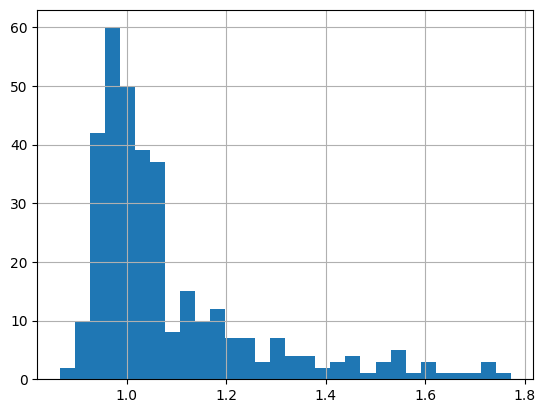

In [ ]:
cn_pet["SUMMARY_SUVR"].hist(bins=30)

In [ ]:
cn_pet["amyloid_label"] = (
    cn_pet["SUMMARY_SUVR"] > 1.11
).astype(int)

cn_pet["amyloid_label"].value_counts()

,count
amyloid_label,
0,256
1,97


In [ ]:
cn_full = pd.merge(
    cn_pet,
    df_plasma[
        [
            "RID",
            "VISCODE",
            "pT217_F",
            "AB42_AB40_F",
            "NfL_Q",
            "GFAP_Q"
        ]
    ],
    on=["RID", "VISCODE"],
    how="inner"
)

print(cn_full.shape)

cn_full.head()

(238, 47)


,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,DIAGNOSIS,DXNORM,DXNODEP,DXMCI,...,DD_CRF_VERSION_LABEL,LANGUAGE_CODE,HAS_QC_ERROR,update_stamp,SUMMARY_SUVR,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q
0,ADNI3,027_S_6001,6001,bl,bl,2017-01-19,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2017-10-26 14:25:11,1.008,0,0.386,0.0973,27.5,175.4
1,ADNI3,024_S_6005,6005,bl,bl,2017-05-03,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2017-10-26 14:25:11,1.072,0,0.105,0.0843,9.8,181.3
2,ADNI3,141_S_6015,6015,bl,bl,2017-05-26,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2017-10-26 14:25:11,1.033,0,1.291,0.0839,34.4,304.4
3,ADNI3,002_S_6009,6009,bl,bl,2017-05-16,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2017-10-26 14:25:11,1.023,0,0.111,0.0857,12.2,100.8
4,ADNI3,941_S_6044,6044,bl,bl,2017-07-12,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2017-10-26 14:25:11,1.524,1,0.627,0.0885,26.5,209.3


In [ ]:
cn_full = pd.merge(
    cn_full,
    df_apoe[["RID", "GENOTYPE"]],
    on="RID",
    how="left"
)

print(cn_full.shape)

cn_full[["RID", "GENOTYPE"]].head()

(238, 48)


,RID,GENOTYPE
0,6001,2/3
1,6005,3/4
2,6015,3/3
3,6009,3/4
4,6044,4/4


In [ ]:
cn_full[["GENOTYPE"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   GENOTYPE  238 non-null    object
dtypes: object(1)
memory usage: 2.0+ KB


# feature engineering

In [ ]:
cn_full["APOE4"] = cn_full["GENOTYPE"].apply(
    lambda x: 1 if "4" in str(x) else 0
)

cn_full["APOE4"].value_counts()

,count
APOE4,
0,155
1,83


In [ ]:
pd.crosstab(cn_full["APOE4"], cn_full["amyloid_label"])

amyloid_label,0,1
APOE4,,
0,131,24
1,48,35


In [ ]:
cn_full = pd.merge(
    cn_full,
    df_demo[
        [
            "RID",
            "VISCODE",
            "PTGENDER",
            "PTDOBYY",
            "PTEDUCAT"
        ]
    ],
    on=["RID", "VISCODE"],
    how="left"
)

print(cn_full.shape)

(238, 52)


In [ ]:
important_cols = [
    "amyloid_label",
    "pT217_F",
    "AB42_AB40_F",
    "NfL_Q",
    "GFAP_Q",
    "APOE4",
    "PTGENDER",
    "PTDOBYY",
    "PTEDUCAT"
]

cn_full[important_cols].isnull().sum()

,0
amyloid_label,0
pT217_F,0
AB42_AB40_F,0
NfL_Q,0
GFAP_Q,0
APOE4,0
PTGENDER,238
PTDOBYY,238
PTEDUCAT,238


In [ ]:
demo_small = df_demo[
    [
        "RID",
        "PTGENDER",
        "PTDOBYY",
        "PTEDUCAT"
    ]
].drop_duplicates(subset="RID")

In [ ]:
cn_full = cn_full.drop(
    columns=["PTGENDER", "PTDOBYY", "PTEDUCAT"]
)

cn_full = pd.merge(
    cn_full,
    demo_small,
    on="RID",
    how="left"
)

cn_full[
    [
        "PTGENDER",
        "PTDOBYY",
        "PTEDUCAT"
    ]
].isnull().sum()

,0
PTGENDER,0
PTDOBYY,0
PTEDUCAT,0


In [ ]:
cn_full[
    [
        "PTGENDER",
        "PTDOBYY",
        "PTEDUCAT"
    ]
].describe()

,PTGENDER,PTEDUCAT
count,238.000000,238.000000
mean,1.634454,16.739496
std,0.482598,2.122661
min,1.000000,11.000000
25%,1.000000,16.000000
50%,2.000000,16.000000
75%,2.000000,18.000000
max,2.000000,20.000000


In [ ]:
cn_full["PTDOBYY"].describe()

,PTDOBYY
count,238
unique,38
top,1/1/1951
freq,25


In [ ]:
cn_full[cn_full.duplicated(subset=["RID", "VISCODE"])]

,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,DIAGNOSIS,DXNORM,DXNODEP,DXMCI,...,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,GENOTYPE,APOE4,PTGENDER,PTDOBYY,PTEDUCAT


In [ ]:
cn_full["PTDOBYY"] = pd.to_datetime(
    cn_full["PTDOBYY"]
)

In [ ]:
cn_full["BIRTH_YEAR"] = cn_full["PTDOBYY"].dt.year

cn_full["BIRTH_YEAR"].head()

,BIRTH_YEAR
0,1944
1,1949
2,1949
3,1949
4,1942


In [ ]:
cn_full["PTDOBYY"] = pd.to_datetime(
    cn_full["PTDOBYY"]
)

cn_full["EXAMDATE"] = pd.to_datetime(
    cn_full["EXAMDATE"]
)

In [ ]:
cn_full["AGE"] = (
    (cn_full["EXAMDATE"] - cn_full["PTDOBYY"])
    .dt.days / 365.25
)

cn_full["AGE"].describe()

,AGE
count,238.000000
mean,70.231763
std,6.826679
min,51.014374
25%,66.631075
50%,69.624914
75%,74.568789
max,91.137577


In [ ]:
cn_full["AGE"]

,AGE
0,73.051335
1,68.334018
2,68.396988
3,68.369610
4,75.526352
...,...
233,63.764545
234,66.171116
235,65.886379
236,81.374401


In [ ]:
cn_full["SEX"] = cn_full["PTGENDER"].map({
    1: 1,   # Male
    2: 0    # Female
})

In [ ]:
ml_dataset = cn_full[
    [
        "RID",
        "amyloid_label",
        "pT217_F",
        "AB42_AB40_F",
        "NfL_Q",
        "GFAP_Q",
        "APOE4",
        "AGE",
        "SEX",
        "PTEDUCAT",
        "EXAMDATE",
        "PTID"
    ]
]

ml_dataset.to_csv(
    "biomarkers.csv",
    index=False
)

print("saved successfully")

saved successfully


In [ ]:
df.head()

NameError: name 'df' is not defined

In [ ]:
# df = pd.read_csv("amyloid_with_examdate_dataset.csv")